In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: []


In [2]:
DATASET_DIR = "../parking_dataset/clf-data"

for class_name in ["empty", "not_empty"]:
    folder = os.path.join(DATASET_DIR, class_name)
    print(class_name, "exists:", os.path.isdir(folder))
    print(
        class_name,
        "image files:",
        sum(
            1 for name in os.listdir(folder)
            if os.path.isfile(os.path.join(folder, name))
        )
    )

empty exists: True
empty image files: 3045
not_empty exists: True
not_empty image files: 3045


Found 6090 files belonging to 2 classes.
Using 4872 files for training.
Found 6090 files belonging to 2 classes.
Using 1218 files for validation.
Class names: ['empty', 'not_empty']


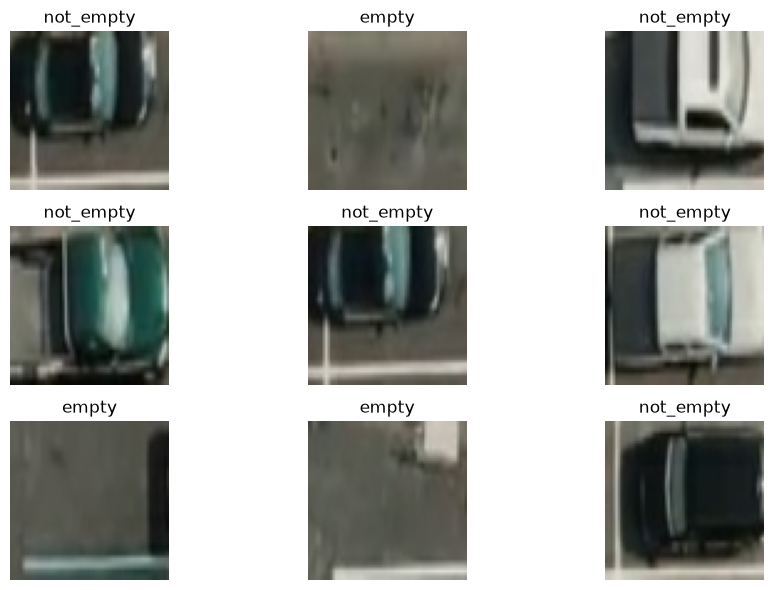

In [3]:
from tensorflow.keras.utils import image_dataset_from_directory

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

train_ds = image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_test_ds = image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Class names:", class_names)

plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

train_ds = image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

temp_ds = image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Split the remaining 30% into validation and test sets
temp_batches = list(temp_ds)
val_count = len(temp_batches) // 2

val_ds = tf.data.Dataset.from_tensor_slices(
    (
        tf.concat([x for x, y in temp_batches[:val_count]], axis=0),
        tf.concat([y for x, y in temp_batches[:val_count]], axis=0)
    )
).batch(BATCH_SIZE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        tf.concat([x for x, y in temp_batches[val_count:]], axis=0),
        tf.concat([y for x, y in temp_batches[val_count:]], axis=0)
    )
).batch(BATCH_SIZE)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Found 6090 files belonging to 2 classes.
Using 4263 files for training.
Found 6090 files belonging to 2 classes.
Using 1827 files for validation.
Training batches: 134
Validation batches: 29
Testing batches: 29


In [5]:
# ANN model
ann_model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,581,313 (6.03 MB)

 Trainable params: 1,581,313 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
ann_history = ann_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


/Users/jyoya/Desktop/Parking_Space_ Detection /.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


134/134 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7795 - loss: 0.5528 - val_accuracy: 0.9138 - val_loss: 0.2828
Epoch 2/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8862 - loss: 0.3041 - val_accuracy: 0.9515 - val_loss: 0.1686
Epoch 3/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9146 - loss: 0.2428 - val_accuracy: 0.9407 - val_loss: 0.2298
Epoch 4/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9167 - loss: 0.2500 - val_accuracy: 0.9601 - val_loss: 0.1664
Epoch 5/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9233 - loss: 0.2268 - val_accuracy: 0.9601 - val_loss: 0.1480
Epoch 6/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9275 - loss: 0.2077 - val_accuracy: 0.9343 - val_loss: 0.1822
Epoch 7/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9017 - loss: 0.2590 - val_accuracy: 0.9170 - val_loss: 0.2119
Epoch 8/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9181 - loss: 0.2225 - val_accuracy: 0.9580 - val_

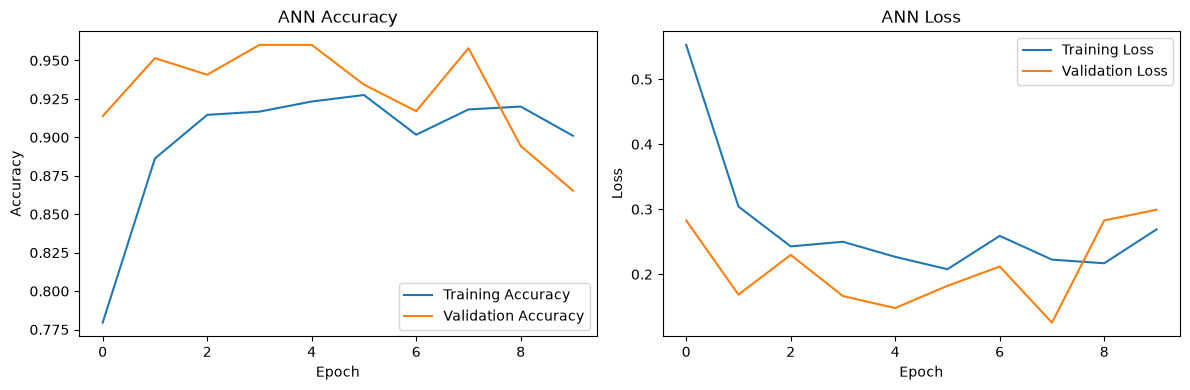

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(ann_history.history["accuracy"], label="Training Accuracy")
plt.plot(ann_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ann_history.history["loss"], label="Training Loss")
plt.plot(ann_history.history["val_loss"], label="Validation Loss")
plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
# Get true labels from the test dataset
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

# Predict probabilities
y_prob_ann = ann_model.predict(test_ds).ravel()

# Convert probabilities into class predictions
y_pred_ann = (y_prob_ann >= 0.5).astype(int)

# Calculate performance metrics
ann_precision = precision_score(y_true, y_pred_ann, zero_division=0)
ann_recall = recall_score(y_true, y_pred_ann, zero_division=0)
ann_f1 = f1_score(y_true, y_pred_ann, zero_division=0)
ann_auc = roc_auc_score(y_true, y_prob_ann)

print("ANN Model Evaluation")
print("--------------------")
print(f"Precision: {ann_precision:.4f}")
print(f"Recall:    {ann_recall:.4f}")
print(f"F1 Score:  {ann_f1:.4f}")
print(f"ROC-AUC:   {ann_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred_ann,
    target_names=class_names,
    zero_division=0
))

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
ANN Model Evaluation
--------------------
Precision: 0.8197
Recall:    0.9265
F1 Score:  0.8698
ROC-AUC:   0.9440

Classification Report:
              precision    recall  f1-score   support

       empty       0.90      0.77      0.83       423
   not_empty       0.82      0.93      0.87       476

    accuracy                           0.85       899
   macro avg       0.86      0.85      0.85       899
weighted avg       0.86      0.85      0.85       899



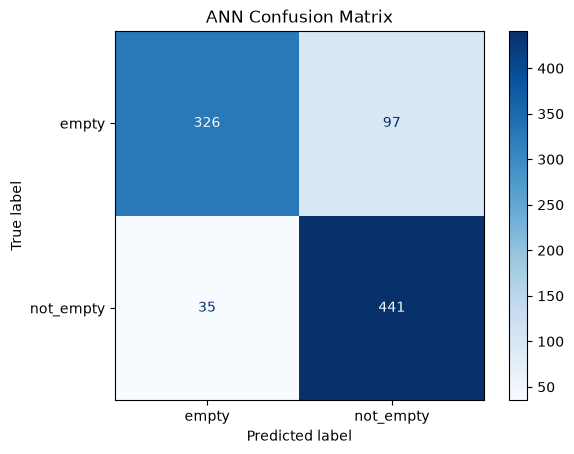

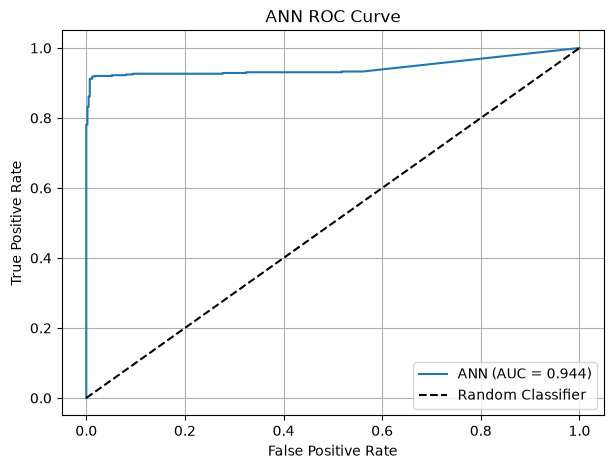

In [9]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred_ann)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues")
plt.title("ANN Confusion Matrix")
plt.show()

# ROC curve
fpr_ann, tpr_ann, _ = roc_curve(y_true, y_prob_ann)

plt.figure(figsize=(7, 5))
plt.plot(fpr_ann, tpr_ann, label=f"ANN (AUC = {ann_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ANN ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# CNN model
cnn_model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


/Users/jyoya/Desktop/Parking_Space_ Detection /.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


134/134 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9357 - loss: 0.1614 - val_accuracy: 0.9946 - val_loss: 0.0155
Epoch 2/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9948 - loss: 0.0199 - val_accuracy: 0.9946 - val_loss: 0.0101
Epoch 3/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9955 - loss: 0.0160 - val_accuracy: 0.9957 - val_loss: 0.0073
Epoch 4/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9993 - loss: 0.0017 - val_accuracy: 0.9946 - val_loss: 0.0099
Epoch 5/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9995 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 6.5562e-04
Epoch 6/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 1.0000 - loss: 2.6875e-04 - val_accuracy: 1.0000 - val_loss: 9.6196e-05
Epoch 7/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 1.0000 - loss: 6.9835e-05 - val_accuracy: 1.0000 - val_loss: 1.6154e-04
Epoch 8/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9876 - loss: 0.0497 -

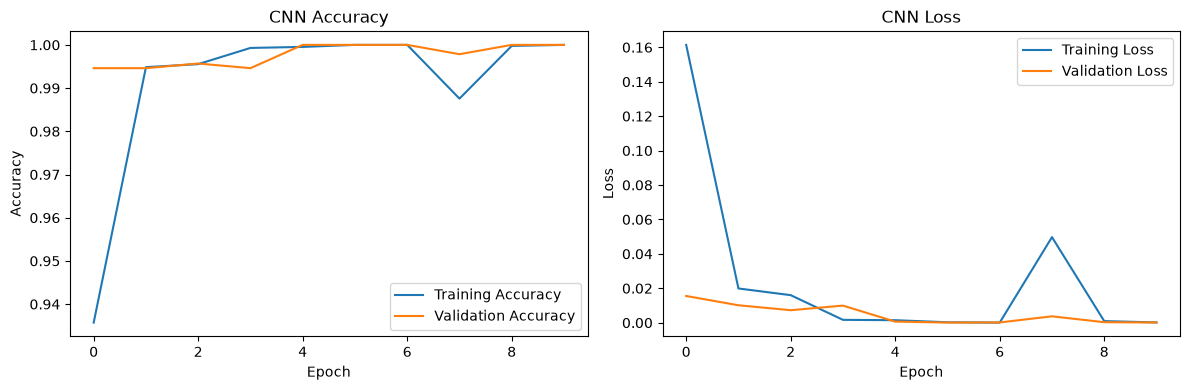

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
y_prob_cnn = cnn_model.predict(test_ds).ravel()
y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

cnn_precision = precision_score(y_true, y_pred_cnn, zero_division=0)
cnn_recall = recall_score(y_true, y_pred_cnn, zero_division=0)
cnn_f1 = f1_score(y_true, y_pred_cnn, zero_division=0)
cnn_auc = roc_auc_score(y_true, y_prob_cnn)

print("CNN Model Evaluation")
print("--------------------")
print(f"Precision: {cnn_precision:.4f}")
print(f"Recall:    {cnn_recall:.4f}")
print(f"F1 Score:  {cnn_f1:.4f}")
print(f"ROC-AUC:   {cnn_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred_cnn,
    target_names=class_names,
    zero_division=0
))

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
CNN Model Evaluation
--------------------
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
ROC-AUC:   1.0000

Classification Report:
              precision    recall  f1-score   support

       empty       1.00      1.00      1.00       423
   not_empty       1.00      1.00      1.00       476

    accuracy                           1.00       899
   macro avg       1.00      1.00      1.00       899
weighted avg       1.00      1.00      1.00       899



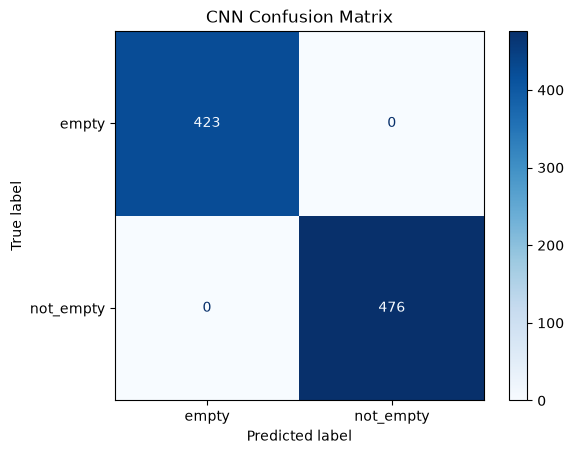

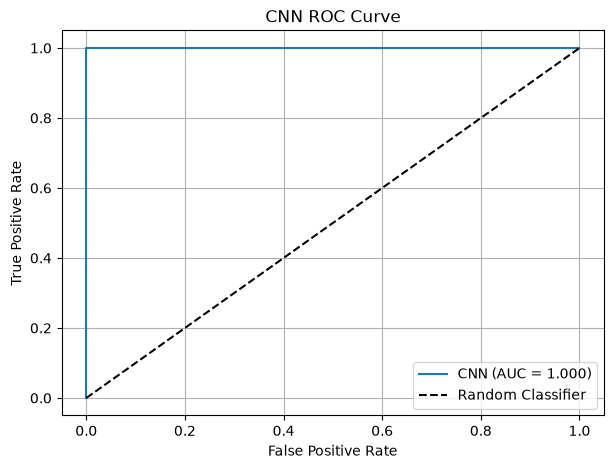

In [14]:
cm_cnn = confusion_matrix(y_true, y_pred_cnn)

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=class_names
).plot(cmap="Blues")

plt.title("CNN Confusion Matrix")
plt.show()

fpr_cnn, tpr_cnn, _ = roc_curve(y_true, y_prob_cnn)

plt.figure(figsize=(7, 5))
plt.plot(fpr_cnn, tpr_cnn, label=f"CNN (AUC = {cnn_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Compare both models
results = pd.DataFrame({
    "Model": ["ANN", "CNN"],
    "Precision": [ann_precision, cnn_precision],
    "Recall": [ann_recall, cnn_recall],
    "F1 Score": [ann_f1, cnn_f1],
    "ROC-AUC": [ann_auc, cnn_auc]
})

print(results.round(4).to_string(index=False))

Model  Precision  Recall  F1 Score  ROC-AUC
  ANN     0.8197  0.9265    0.8698    0.944
  CNN     1.0000  1.0000    1.0000    1.000


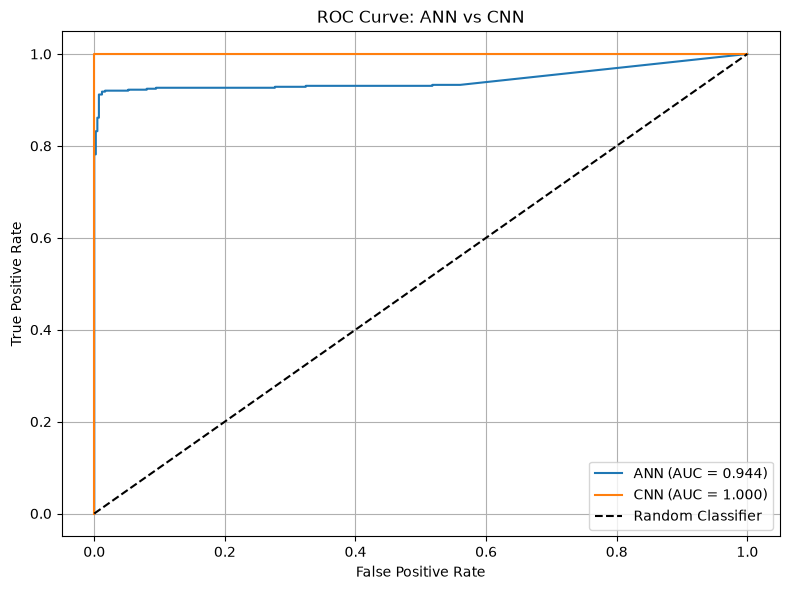

In [16]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_ann, tpr_ann,
    label=f"ANN (AUC = {ann_auc:.3f})"
)
plt.plot(
    fpr_cnn, tpr_cnn,
    label=f"CNN (AUC = {cnn_auc:.3f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: ANN vs CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
os.makedirs("results", exist_ok=True)

results.to_csv("results/model_comparison.csv", index=False)

ann_model.save("results/parking_ann.keras")
cnn_model.save("results/parking_cnn.keras")

print("Comparison table and trained models saved successfully.")

Comparison table and trained models saved successfully.
